# AutoFeatureRec · KION
**Задание 1: автоматическая генерация и отбор признаков рекомендательной системы**

Colab CPU · CatBoost · временные срезы · ручные признаки vs автоматически сгенерированные.

**Протокол:** на каждом срезе времени признаки доступны только из истории до `cutoff`; положительные объекты — просмотры в следующем интервале; отрицательные — случайно выбранные кандидаты из доступного на `cutoff` каталога, отсутствующие в истории пользователя и положительных событиях интервала. Это **sampled unobserved items, не подтверждённые отказы**. Метрики зависят от этой схемы кандидатов. Разбиение train/validation/test выполняется по времени, test не участвует в подборе.

**Как запускать:** Runtime → Run all. Для быстрой отладки задайте `N_USERS = 5000`, для итогового эксперимента попробуйте `15000–30000`. Результаты и README сохраняются в `/content/autofeaturerec_results/`. Все результаты считаются при запуске, числа заранее не подставлены.

**Ограничение KION:** в открытой таблице хранится `last_watch_dt`, а не полный поток пользовательских показов. Мы интерпретируем записи как датированные взаимодействия и оговариваем ограничение в выводах.

**Исследовательская версия:** E0 популярность, E1 ручной baseline, E2 auto, E3 hybrid, E4 без временных окон. Подбор только на validation, итоговый test после выбора.

## 1. Зависимости и параметры

**Рекомендуемая среда:** Google Colab → CPU (высокая RAM при наличии). GPU не нужен: CatBoost обучается на CPU с `thread_count=2`. Запуск: Runtime → Run all. Для быстрой диагностики сначала `N_USERS=5000`, для итогового запуска `15000`, если хватает времени. Скачайте ZIP с результатами после завершения.

In [1]:
!pip -q install catboost pyarrow

In [2]:
from pathlib import Path
from datetime import timedelta
from collections import defaultdict
import os, time, random, zipfile, urllib.request, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, log_loss
from IPython.display import display

SEED = 42
N_USERS = 15000              # 5000 для быстрого пробного запуска
NEG_PER_POS = 15             # баланс скорости и качества
MAX_POS_PER_USER = 4         # ограничение количества положительных кандидатов на пользователя/срез
WINDOWS = [3, 7, 14, 30, 60, 120]
BASE_WINDOWS = [7, 30]
TRAIN_ITERATIONS = 200
OUT = Path('/content/autofeaturerec_results'); OUT.mkdir(exist_ok=True)
DATA = Path('/content/kion_data'); DATA.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
print('Параметры:', {'users':N_USERS, 'neg_per_pos':NEG_PER_POS, 'windows':WINDOWS})

Параметры: {'users': 15000, 'neg_per_pos': 15, 'windows': [3, 7, 14, 30, 60, 120]}


## 2. Получение KION и обзор схемы
Оригинальные файлы: [официальный репозиторий](https://github.com/irsafilo/KION_DATASET).

In [3]:
archive = DATA / 'data_original.zip'
urls = [
    'https://github.com/irsafilo/KION_DATASET/raw/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip',
    'https://raw.githubusercontent.com/irsafilo/KION_DATASET/main/data_original.zip',
    'https://github.com/irsafilo/KION_DATASET/raw/refs/heads/main/data_original.zip',
]
if not archive.exists() or not zipfile.is_zipfile(archive):
    if archive.exists(): archive.unlink()
    for url in urls:
        try:
            print('Загружаем:', url)
            urllib.request.urlretrieve(url, archive)
            if not zipfile.is_zipfile(archive): raise ValueError('Получен не ZIP')
            break
        except Exception as e:
            print('Попытка не удалась:', str(e)[:170])
            if archive.exists(): archive.unlink()
    else:
        raise RuntimeError('Не получилось загрузить ZIP. Откройте GitHub и загрузите data_original.zip вручную в /content/kion_data/')
with zipfile.ZipFile(archive) as z:
    print('В архиве:', z.namelist()[:12]); z.extractall(DATA)
files = {p.name.lower():p for p in DATA.rglob('*.csv')}
assert all(k in files for k in ('interactions.csv','users.csv','items.csv')), list(files)
interactions = pd.read_csv(files['interactions.csv'], parse_dates=['last_watch_dt'])
users = pd.read_csv(files['users.csv'])
items = pd.read_csv(files['items.csv'])
print('Размеры:', interactions.shape, users.shape, items.shape)
print('Колонки interactions:', interactions.columns.tolist())
display(interactions.head(3)); display(items.head(2))

Загружаем: https://github.com/irsafilo/KION_DATASET/raw/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip
В архиве: ['data_original/', 'data_original/interactions.csv', '__MACOSX/data_original/._interactions.csv', 'data_original/users.csv', '__MACOSX/data_original/._users.csv', 'data_original/items.csv', '__MACOSX/data_original/._items.csv']
Размеры: (5476251, 5) (840197, 5) (15963, 14)
Колонки interactions: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct']


,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0


,item_id,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,directors,actors,description,keywords
0,10711,film,Поговори с ней,Hable con ella,2002.0,"драмы, зарубежные, детективы, мелодрамы",Испания,NaN,16.0,NaN,Педро Альмодовар,"Адольфо Фернандес, Ана Фернандес, Дарио Гранди...",Мелодрама легендарного Педро Альмодовара «Пого...,"Поговори, ней, 2002, Испания, друзья, любовь, ..."
1,2508,film,Голые перцы,Search Party,2014.0,"зарубежные, приключения, комедии",США,NaN,16.0,NaN,Скот Армстронг,"Адам Палли, Брайан Хаски, Дж.Б. Смув, Джейсон ...",Уморительная современная комедия на популярную...,"Голые, перцы, 2014, США, друзья, свадьбы, прео..."


## 3. Сэмплирование пользователей: полная история каждого выбранного пользователя

In [4]:
selected = np.random.default_rng(SEED).choice(interactions['user_id'].unique(), size=min(N_USERS, interactions['user_id'].nunique()), replace=False)
events = interactions.loc[interactions['user_id'].isin(selected), ['user_id','item_id','last_watch_dt']].copy()
events = events.rename(columns={'last_watch_dt':'ts'}).dropna(subset=['ts'])
events['ts'] = pd.to_datetime(events['ts'])
events = events.sort_values(['ts','user_id','item_id']).reset_index(drop=True)
# Запись KION часто уже агрегирована на уровне пары user–item; не считаем несколько просмотров из неё.
events = events.drop_duplicates(['user_id','item_id','ts'])
print('События:',len(events),'пользователи:',events.user_id.nunique(),'объекты:',events.item_id.nunique())
print('Период:', events.ts.min(), '—', events.ts.max())
print('Средняя история:',round(len(events)/events.user_id.nunique(),2))
assert events.ts.notna().all()
del interactions  # освобождаем память

События: 86492 пользователи: 15000 объекты: 5837
Период: 2021-03-13 00:00:00 — 2021-08-22 00:00:00
Средняя история: 5.77


## 4. Категории фильмов и временные срезы
Жанр — статическая метаинформация, доступная до целевого взаимодействия. Train = первые 2 среза, validation = третий, test = четвёртый.

In [5]:
assert 'item_id' in items.columns
meta = items[['item_id']].copy()
if 'genres' in items.columns:
    meta['genre'] = items['genres'].fillna('unknown').astype(str).str.split(',').str[0].str.strip().replace('', 'unknown')
else:
    meta['genre'] = 'unknown'
meta = meta.drop_duplicates('item_id')
# границы по календарному времени, а не по строкам
start, finish = events.ts.min(), events.ts.max()
fracs = [0.40,0.55,0.70,0.85,1.0]
bounds = [start + (finish-start)*f for f in fracs]
print('Срезы:', [(str(a.date()),str(b.date())) for a,b in zip(bounds[:-1],bounds[1:])])
assert len(set(bounds)) == 5, 'Очень короткий временной диапазон'
# хранение только нужных полей уменьшает память
events = events.merge(meta, on='item_id', how='left')
events['genre'] = events['genre'].fillna('unknown')
assert events['ts'].is_monotonic_increasing


Срезы: [('2021-05-16', '2021-06-10'), ('2021-06-10', '2021-07-04'), ('2021-07-04', '2021-07-28'), ('2021-07-28', '2021-08-22')]


## 5. Генерация кандидатов без заглядывания в будущее
На срезе каждый пользователь с хотя бы одной новой активностью получает положительные объекты в следующем окне и до `NEG_PER_POS` случайных кандидатов на каждый положительный. Каталог и частоты для выборки кандидатов определяются **только по прошлому**; не исключаем будущие просмотры за пределами оцениваемого окна.

In [6]:
def make_candidates(history, future, snap_id, max_negs=NEG_PER_POS):
    rng = np.random.default_rng(SEED + snap_id)
    catalog = history['item_id'].drop_duplicates().to_numpy()
    if len(catalog) < 30:
        raise ValueError('Каталог в истории слишком маленький')
    # ограничиваем целевых пользователей теми, для кого есть история на момент среза
    known_users = set(history['user_id'].unique())
    active = future[future.user_id.isin(known_users)]
    seen = history.groupby('user_id')['item_id'].agg(set).to_dict()
    available = set(catalog)
    positives = (active[active.item_id.isin(available)]
                 .drop_duplicates(['user_id','item_id'])
                 .sort_values(['user_id','ts']))
    rows = []
    for uid, group in positives.groupby('user_id', sort=False):
        pos_ids = group['item_id'].to_numpy()[:MAX_POS_PER_USER]
        pos_set = set(group.item_id.tolist())  # предотвращаем false negatives для окна
        blocked = seen[uid] | pos_set
        rows.extend((snap_id, uid, int(i), 1) for i in pos_ids)
        eligible = np.array([i for i in catalog if i not in blocked], dtype=catalog.dtype)
        nneg = min(len(eligible), max_negs * len(pos_ids))
        if nneg:
            negs = rng.choice(eligible, size=nneg, replace=False)
            rows.extend((snap_id, uid, int(i), 0) for i in negs)
    result = pd.DataFrame(rows, columns=['snapshot','user_id','item_id','label'])
    result = result.merge(meta, on='item_id', how='left')
    result['genre'] = result['genre'].fillna('unknown')
    return result

snapshots = []
for snap_id, (cutoff, next_cutoff) in enumerate(zip(bounds[:-1],bounds[1:])):
    hist = events[events.ts < cutoff]
    fut = events[(events.ts >= cutoff) & (events.ts < next_cutoff if snap_id < 3 else events.ts <= next_cutoff)]
    cand = make_candidates(hist, fut, snap_id)
    assert not cand.duplicated(['snapshot','user_id','item_id']).any()
    assert cand.label.nunique() == 2, f'Нет обоих классов в срезе {snap_id}'
    snapshots.append(cand)
    print(f'{snap_id}: cutoff={cutoff.date()}, history={len(hist)}, future={len(fut)}, candidates={len(cand)}, positives={cand.label.sum()}, users={cand.user_id.nunique()}')


0: cutoff=2021-05-16, history=18600, future=11423, candidates=43456, positives=2716, users=1163
1: cutoff=2021-06-10, history=30023, future=17049, candidates=82128, positives=5133, users=2087
2: cutoff=2021-07-04, history=47072, future=17369, candidates=87888, positives=5493, users=2325
3: cutoff=2021-07-28, history=64441, future=22051, candidates=106480, positives=6655, users=2754


## 6. Признаки на каждом временном срезе
**Ручной baseline:** user/item/genre агрегаты за всё прошлое и окна 7,30 дней; user–genre affinity; категориальный жанр. **Auto:** алгоритмически перебираем `entity × window × count/nunique` для окон 3,7,14,30,60,120. Ни целевое событие, ни события после cutoff не используются.

In [7]:
KEYS = {'user':['user_id'], 'item':['item_id'], 'genre':['genre'], 'user_genre':['user_id','genre']}

def add_aggs(frame, hist, label):
    out = frame.copy()
    for entity, keys in KEYS.items():
        group = hist.groupby(keys, dropna=False)['item_id'].agg(['size','nunique']).reset_index()
        group = group.rename(columns={'size':f'{label}_{entity}_cnt', 'nunique':f'{label}_{entity}_nunique'})
        out = out.merge(group, on=keys, how='left', validate='many_to_one')
    return out

def create_features(candidates, cutoff, full_history):
    t0 = time.monotonic()
    hist = full_history[full_history.ts < cutoff]
    x = add_aggs(candidates, hist, 'all')
    for days in WINDOWS:
        recent = hist[hist.ts >= cutoff - pd.Timedelta(days=days)]
        x = add_aggs(x, recent, f'w{days}')
    numeric_cols = [c for c in x if c.endswith(('_cnt','_nunique'))]
    x[numeric_cols] = x[numeric_cols].fillna(0).astype('float32')
    x['genre'] = x['genre'].astype(str)
    return x, time.monotonic()-t0

features = []; costs=[]
for sid,(cand,cutoff) in enumerate(zip(snapshots,bounds[:-1])):
    x,sec = create_features(cand,cutoff,events)
    features.append(x);costs.append(sec)
    print(f'Snapshot {sid}: {len(x)} rows × {len(x.columns)} columns; feature generation {sec:.1f}s')
all_data = pd.concat(features,ignore_index=True)
train = all_data[all_data.snapshot.isin([0,1])].copy()
valid = all_data[all_data.snapshot == 2].copy()
test = all_data[all_data.snapshot == 3].copy()
print('Train/Val/Test:',len(train),len(valid),len(test))
assert train.label.nunique() == valid.label.nunique() == test.label.nunique() == 2
assert set(train.snapshot).isdisjoint(valid.snapshot)
assert set(test.snapshot).isdisjoint(train.snapshot)


Snapshot 0: 43456 rows × 61 columns; feature generation 0.7s
Snapshot 1: 82128 rows × 61 columns; feature generation 1.1s
Snapshot 2: 87888 rows × 61 columns; feature generation 1.6s
Snapshot 3: 106480 rows × 61 columns; feature generation 1.8s
Train/Val/Test: 125584 87888 106480


## 7. Определяем наборы признаков
Ручной набор задаём **до** результатов эксперимента. Автоматический набор генерируется из декартова произведения сущностей, окон и агрегатов. Отбор автоматических признаков выполняется с помощью feature importance и валидации без использования test.

In [8]:
all_numeric = [c for c in all_data.columns if c.endswith(('_cnt','_nunique'))]
alltime = [c for c in all_numeric if c.startswith('all_')]
manual = ['genre'] + alltime + [c for c in all_numeric if c.startswith(tuple(f'w{d}_' for d in BASE_WINDOWS)) and c.endswith('_cnt')]
auto = ['genre'] + all_numeric
manual = list(dict.fromkeys(manual)); auto=list(dict.fromkeys(auto))
print('Manual features:',len(manual));print('Auto candidates:',len(auto))
print('Auto windows:',WINDOWS)
assert set(manual).issubset(auto)


Manual features: 17
Auto candidates: 57
Auto windows: [3, 7, 14, 30, 60, 120]


## 8. Обучение CatBoost и оценка классификации + ранжирования
NDCG@10 вычисляем **внутри одинаковых списков кандидатов на пользователя**, а не по разным наборам кандидатов.

In [9]:
def ndcg10(frame, probabilities, k=10):
    tmp = frame[['snapshot','user_id','label']].copy()
    tmp['score'] = probabilities
    vals=[]
    for _,part in tmp.groupby(['snapshot','user_id'],sort=False):
        labels = part.sort_values('score',ascending=False)['label'].to_numpy()[:k]
        gains = labels/np.log2(np.arange(2,len(labels)+2))
        ideal_n = min(int(part.label.sum()),k)
        ideal = np.sum(1/np.log2(np.arange(2,ideal_n+2))) if ideal_n else 0
        if ideal: vals.append(np.sum(gains)/ideal)
    return float(np.mean(vals)) if vals else np.nan

def metrics(frame, pred):
    y=frame.label.to_numpy()
    return {'ROC-AUC':roc_auc_score(y,pred),
            'LogLoss':log_loss(y,np.clip(pred,1e-7,1-1e-7)),
            'NDCG@10':ndcg10(frame,pred)}

def fit_model(cols, iterations=TRAIN_ITERATIONS):
    m=CatBoostClassifier(iterations=iterations,depth=6,learning_rate=0.07,loss_function='Logloss',
         random_seed=SEED,verbose=False,thread_count=2,allow_writing_files=False, l2_leaf_reg=5)
    cats = [c for c in cols if train[c].dtype=='object']
    t=time.monotonic()
    m.fit(train[cols],train.label,cat_features=cats)
    elapsed=time.monotonic()-t
    return m,elapsed

results=[];models={}; feature_sets={}
def evaluate(name, cols):
    model,secs=fit_model(cols)
    pv=model.predict_proba(valid[cols])[:,1]
    mv=metrics(valid,pv)
    results.append({'model':name,'num_features':len(cols),'fit_seconds':secs,**{'val_'+k:v for k,v in mv.items()}})
    models[name]=model;feature_sets[name]=cols
    print(name, 'features=',len(cols),'training seconds=',round(secs,1), 'validation=',{k:round(v,4) for k,v in mv.items()})

evaluate('Manual',manual)
evaluate('Auto_all',auto)
# E0: популярность объекта, без персонализации
popularity = ['all_item_cnt']
evaluate('Popularity', popularity)
# E4: только накопленная история, без временных окон
evaluate('No_temporal', ['genre'] + alltime)


Manual features= 17 training seconds= 30.0 validation= {'ROC-AUC': np.float64(0.8749), 'LogLoss': 0.1527, 'NDCG@10': 0.7218}
Auto_all features= 57 training seconds= 31.0 validation= {'ROC-AUC': np.float64(0.8762), 'LogLoss': 0.1523, 'NDCG@10': 0.7231}
Popularity features= 1 training seconds= 7.0 validation= {'ROC-AUC': np.float64(0.8419), 'LogLoss': 0.1676, 'NDCG@10': 0.6794}
No_temporal features= 9 training seconds= 27.4 validation= {'ROC-AUC': np.float64(0.8567), 'LogLoss': 0.1617, 'NDCG@10': 0.6909}


## 9. Автоматический отбор признаков и проверка гипотезы
Вместо ручного задания окон выбираем топ-K по важности, полученной **только на train**, а значение K выбираем **только на validation**. `genre` оставляем обязательным категориальным признаком. Это воспроизводимый алгоритм автоматического выбора признаков.

In [10]:
imp = pd.Series(models['Auto_all'].get_feature_importance(),index=auto).drop('genre',errors='ignore').sort_values(ascending=False)
display(imp.head(20).rename('importance').to_frame())
for k in [8,16,32]:
    selected_cols=['genre'] + imp.head(min(k,len(imp))).index.tolist()
    evaluate(f'Auto_top{k}',selected_cols)
# E3: объединение ручных признаков и top-K автоматически найденных
for k in [8,16]:
    hybrid_cols=list(dict.fromkeys(manual + imp.head(min(k,len(imp))).index.tolist()))
    evaluate(f'Hybrid_top{k}',hybrid_cols)
validation_results=pd.DataFrame(results).sort_values('val_NDCG@10',ascending=False)
display(validation_results)
# Чтобы тестовая выборка оставалась честной, окончательный выбор фиксируем по валидации.
best_auto_name=(validation_results[validation_results.model.str.startswith('Auto_')].iloc[0]['model'])
best_hybrid_name=(validation_results[validation_results.model.str.startswith('Hybrid_')].iloc[0]['model'])
print('Лучший автоматический набор по validation NDCG@10:',best_auto_name)
print('Лучший объединённый набор:',best_hybrid_name)


,importance
w60_item_cnt,15.218894
w14_item_cnt,10.140175
w7_item_cnt,9.344874
w120_item_cnt,7.789312
w30_item_cnt,7.784397
all_item_cnt,3.762327
w30_item_nunique,3.360376
w3_item_cnt,2.866611
w3_item_nunique,2.311973
all_user_genre_cnt,2.266208


Auto_top8 features= 9 training seconds= 25.7 validation= {'ROC-AUC': np.float64(0.8667), 'LogLoss': 0.1558, 'NDCG@10': 0.7156}
Auto_top16 features= 17 training seconds= 27.1 validation= {'ROC-AUC': np.float64(0.8759), 'LogLoss': 0.1523, 'NDCG@10': 0.724}
Auto_top32 features= 33 training seconds= 28.7 validation= {'ROC-AUC': np.float64(0.8762), 'LogLoss': 0.1525, 'NDCG@10': 0.7215}
Hybrid_top8 features= 22 training seconds= 27.7 validation= {'ROC-AUC': np.float64(0.8761), 'LogLoss': 0.1525, 'NDCG@10': 0.7226}
Hybrid_top16 features= 28 training seconds= 28.1 validation= {'ROC-AUC': np.float64(0.8771), 'LogLoss': 0.1521, 'NDCG@10': 0.7235}


,model,num_features,fit_seconds,val_ROC-AUC,val_LogLoss,val_NDCG@10
5,Auto_top16,17,27.060374,0.875911,0.152262,0.723988
8,Hybrid_top16,28,28.146451,0.877078,0.152138,0.723478
1,Auto_all,57,30.999022,0.876178,0.152259,0.723053
7,Hybrid_top8,22,27.673345,0.876120,0.152544,0.722556
0,Manual,17,30.017857,0.874897,0.152656,0.721794
6,Auto_top32,33,28.722165,0.876192,0.152495,0.721498
4,Auto_top8,9,25.703724,0.866669,0.155780,0.715609
3,No_temporal,9,27.407883,0.856718,0.161710,0.690943
2,Popularity,1,6.976118,0.841880,0.167602,0.679421


Лучший автоматический набор по validation NDCG@10: Auto_top16
Лучший объединённый набор: Hybrid_top16


## 10. Итоговая оценка на test
Тестовую выборку используем единожды для финального отчёта. Выбранный вариант auto сопоставляем с ручным baseline. Модель не дообучаем на validation, чтобы эксперимент был максимально прозрачным.

In [11]:
final_names=['Popularity','No_temporal','Manual',best_auto_name,best_hybrid_name]
final_rows=[]
for name in final_names:
    cols=feature_sets[name]
    pred=models[name].predict_proba(test[cols])[:,1]
    m=metrics(test,pred)
    final_rows.append({'model':name,'num_features':len(cols),**m})
final=pd.DataFrame(final_rows)
display(final)
final.to_csv(OUT/'final_metrics.csv',index=False)
validation_results.to_csv(OUT/'validation_metrics.csv',index=False)
imp.to_csv(OUT/'feature_importance.csv',header=['importance'])


,model,num_features,ROC-AUC,LogLoss,NDCG@10
0,Popularity,1,0.864469,0.168168,0.677803
1,No_temporal,9,0.876853,0.161329,0.687403
2,Manual,17,0.887256,0.152455,0.719227
3,Auto_top16,17,0.885246,0.153400,0.716242
4,Hybrid_top16,28,0.887956,0.152259,0.719209


## 11. Графики, стоимость генерации и выводы

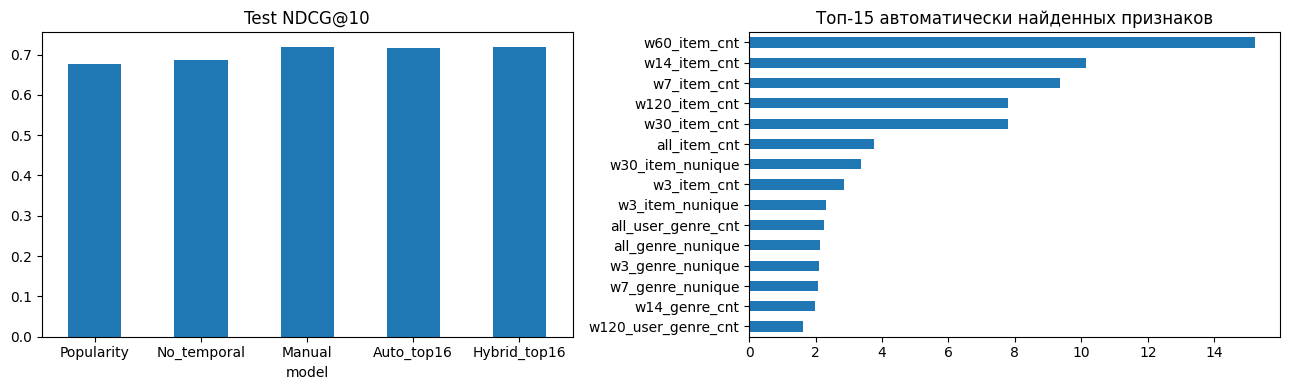

Время расчёта признаков по срезам, сек: [0.66, 1.15, 1.63, 1.8]
Ручной baseline: 17 признаков; Auto: 57 сгенерировано
Выбранные признаки Auto:  ['genre', 'w60_item_cnt', 'w14_item_cnt', 'w7_item_cnt', 'w120_item_cnt', 'w30_item_cnt', 'all_item_cnt', 'w30_item_nunique', 'w3_item_cnt', 'w3_item_nunique', 'all_user_genre_cnt', 'all_genre_nunique', 'w3_genre_nunique', 'w7_genre_nunique', 'w14_genre_cnt', 'w120_user_genre_cnt', 'w120_genre_nunique']


In [12]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
final.plot(x='model',y='NDCG@10',kind='bar',ax=axs[0],legend=False,title='Test NDCG@10')
axs[0].tick_params(axis='x',rotation=0)
imp.head(15).iloc[::-1].plot(kind='barh',ax=axs[1],title='Топ-15 автоматически найденных признаков')
plt.tight_layout();plt.savefig(OUT/'results.png',dpi=160);plt.show()
print('Время расчёта признаков по срезам, сек:',[round(c,2) for c in costs])
print('Ручной baseline:',len(manual),'признаков; Auto:',len(auto),'сгенерировано')
print('Выбранные признаки Auto: ',feature_sets[best_auto_name])


## 12. README и выгрузка артефактов
README формируется на основании **реальных** результатов запуска; экспериментальный код и этот ноутбук приложите в репозиторий. Можно скачать метрики, изображение и README одним ZIP.

In [13]:
m=final.set_index('model')
manual_ndcg=float(m.loc['Manual','NDCG@10']); auto_ndcg=float(m.loc[best_auto_name,'NDCG@10'])
change=auto_ndcg-manual_ndcg
readme=f"""# AutoFeatureRec: автоматический поиск признаков для ранжирования KION

## Задача
Сравнить CatBoost с ручными агрегированными признаками и CatBoost с автоматически сгенерированными/отобранными признаками.

## Данные и ограничения
Открытый KION: https://github.com/irsafilo/KION_DATASET. Случайно выбрано {N_USERS} пользователей, сохранены все доступные записи их истории. Набор содержит implicit feedback; отсутствуют логи экспозиций, поэтому отрицательные примеры — не подтверждённые отказы, а неизученные на данный момент объекты. Метрики применимы только к описанному sampled-candidate протоколу. `last_watch_dt` — дата последнего просмотра, не точная полная последовательность событий.

## Эксперимент
Временные срезы: {[(str(a.date()),str(b.date())) for a,b in zip(bounds[:-1],bounds[1:])]}.
Train: первые 2 среза; validation: 3-й; test: 4-й. Для каждого среза используются только взаимодействия до cutoff; целевое событие и будущее не попадают в признаки. Случайный seed {SEED}, {NEG_PER_POS} отрицательных кандидатов на положительный, до {MAX_POS_PER_USER} положительных на пользователя. Каталог кандидатов определяется по предыдущей истории. Важное ограничение: положительные объекты, не встречавшиеся до cutoff в общем каталоге, не оцениваются (cold-start исключён).

Дополнительные контрольные эксперименты: популярность объекта, удаление временных окон, объединение ручных и автоматически выбранных признаков.

Ручные признаки: агрегаты user/item/genre/user-genre и окна {BASE_WINDOWS} дней. Автогенерация: `entity × window × aggregation`, окна {WINDOWS}, агрегаты count и nunique. CatBoostClassifier. Top-K отбирается на train-importance; величина K выбирается по validation NDCG@10; test не влияет на выбор.

## Результаты на test
{final.to_markdown(index=False, floatfmt='.5f')}

Разница NDCG@10 Auto - Manual: {change:+.5f}. Признаков: ручных {len(manual)}, автоматических {len(feature_sets[best_auto_name])} (выбран {best_auto_name}); гибридный набор: {best_hybrid_name}.

## Ограничения и следующие шаги
- Sampled negatives не являются зарегистрированными отрицательными действиями. Обобщение NDCG на весь каталог не гарантируется.
- У KION разреженные истории и агрегированные user-item взаимодействия, что ограничивает качество персональных агрегатов.
- История отдельных выбранных пользователей сохранена полностью, однако глобальная популярность объектов считается внутри пользовательского поднабора.
- Вычислительные затраты растут примерно с числом окон и группировок. Время создания признаков по срезам: {[round(v,2) for v in costs]} сек.
- Для строгой офлайн-проверки полезны дополнительные временные срезы и независимое повторение с другими seed.

## Научные ориентиры
- Kanter & Veeramachaneni (2015), Deep Feature Synthesis: https://www.featuretools.com/
- Horn et al. (2019), autofeat: https://arxiv.org/abs/1901.07329
- Koren (2009), Collaborative Filtering with Temporal Dynamics: https://doi.org/10.1145/1557019.1557072
Метод является собственной ограниченной процедурой перебора агрегатов, а не точным воспроизведением этих работ.

## Воспроизведение
Открыть `AutoFeatureRec_KION.ipynb` в Google Colab, выполнить Runtime → Run all на CPU. Все библиотеки устанавливаются в первой ячейке. Код загружает открытый датасет и создаёт результаты автоматически. Для расширения эксперимента менять N_USERS и NEG_PER_POS.
"""
(OUT/'README.md').write_text(readme,encoding='utf-8')
print(readme[:1700]); print('Сохранено в',OUT)
import shutil
shutil.make_archive('/content/AutoFeatureRec_results','zip',OUT)
print('Архив: /content/AutoFeatureRec_results.zip')

try:
    from google.colab import files as colab_files
    print('Для скачивания архива выполните: colab_files.download("/content/AutoFeatureRec_results.zip")')
except ImportError:
    pass


# AutoFeatureRec: автоматический поиск признаков для ранжирования KION

## Задача
Сравнить CatBoost с ручными агрегированными признаками и CatBoost с автоматически сгенерированными/отобранными признаками.

## Данные и ограничения
Открытый KION: https://github.com/irsafilo/KION_DATASET. Случайно выбрано 15000 пользователей, сохранены все доступные записи их истории. Набор содержит implicit feedback; отсутствуют логи экспозиций, поэтому отрицательные примеры — не подтверждённые отказы, а неизученные на данный момент объекты. Метрики применимы только к описанному sampled-candidate протоколу. `last_watch_dt` — дата последнего просмотра, не точная полная последовательность событий.

## Эксперимент
Временные срезы: [('2021-05-16', '2021-06-10'), ('2021-06-10', '2021-07-04'), ('2021-07-04', '2021-07-28'), ('2021-07-28', '2021-08-22')].
Train: первые 2 среза; validation: 3-й; test: 4-й. Для каждого среза используются только взаимодействия до cutoff; целевое событие и будущее не попадают в приз

### Перед сдачей
1. Выполните все ячейки (Runtime → Run all), убедитесь, что они завершились без ошибки.
2. Сохраните сам ноутбук через **Файл → Скачать → Скачать .ipynb**.
3. Скачайте `/content/AutoFeatureRec_results.zip` из боковой панели Colab (**Файлы**).
4. Добавьте ноутбук, README и таблицы/графики в GitHub или приложите к отчёту.
5. В отчёте отдельно обсудите, как ограничения sampled negatives влияют на выводы. Результат auto может быть хуже ручных признаков — это допустимый результат исследования.

# AutoFeatureRec — дополнительные исследовательские эксперименты

**Добавь эти ячейки в конец уже выполненного Colab-ноутбука.** Не перезапускай среду: используются `train`, `valid`, `test`, `models`, `feature_sets`, `imp`, `manual`, `auto`, `fit_model`, `metrics`, `SEED`, `OUT`.

**Исследовательские вопросы:** (1) насколько стабилен результат, (2) как качество зависит от числа признаков, (3) что даёт временная динамика, (4) насколько дорого вычислять признаки.

Важно: исходный тест уже был просмотрен. Новые варианты подбираем **только по validation**. Их тестовые результаты, если смотреть после дополнительного подбора, нужно называть *exploratory*, а не независимым подтверждением.

In [14]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

assert all(x in globals() for x in ['train','valid','test','models','feature_sets','imp','manual','auto','fit_model','metrics','SEED','OUT'])
print('Данные доступны:', len(train), len(valid), len(test))
print('Обученные модели:', list(models))


Данные доступны: 125584 87888 106480
Обученные модели: ['Manual', 'Auto_all', 'Popularity', 'No_temporal', 'Auto_top8', 'Auto_top16', 'Auto_top32', 'Hybrid_top8', 'Hybrid_top16']


## A. Bootstrap по пользователям на исходном тесте

Оцениваем доверительные интервалы **разницы средних NDCG@10 по пользователям**. Это диагностика уже зафиксированных исходных моделей, а не способ подбирать новую модель по тесту. Результаты зависят от процедуры negative sampling.

In [15]:
def user_ndcg_table(frame, probabilities, k=10):
    x = frame[['snapshot','user_id','label']].copy()
    x['score'] = np.asarray(probabilities)
    x = x.sort_values(['snapshot','user_id','score'], ascending=[True,True,False], kind='mergesort')
    x['rank'] = x.groupby(['snapshot','user_id']).cumcount() + 1
    x['discounted'] = np.where(x['rank'] <= k, x['label'] / np.log2(x['rank'] + 1), 0.)
    g = x.groupby(['snapshot','user_id'], sort=False)
    dcg = g['discounted'].sum()
    npos = g['label'].sum().clip(upper=k).astype(int)
    discounts = np.r_[0., np.cumsum(1 / np.log2(np.arange(2,k+2)))]
    idcg = pd.Series(discounts[npos.to_numpy()], index=npos.index)
    return (dcg / idcg.replace(0,np.nan)).rename('ndcg').reset_index()

base_names = ['Manual', best_auto_name, best_hybrid_name]
user_scores = {}
for name in base_names:
    cols = feature_sets[name]
    p = models[name].predict_proba(test[cols])[:,1]
    user_scores[name] = user_ndcg_table(test, p).set_index(['snapshot','user_id'])['ndcg']

rng = np.random.default_rng(SEED)
B = 2000
bootstrap_rows = []
for other in base_names[1:]:
    pair = pd.concat([user_scores['Manual'],user_scores[other]],axis=1,keys=['manual','other']).dropna()
    # Кластеризуем по user_id: если пользователь встречается в нескольких срезах,
    # ресэмплируем его целиком.
    differences = (pair['other'] - pair['manual']).groupby(level='user_id').mean().to_numpy()
    draws = rng.choice(differences, size=(B,len(differences)), replace=True).mean(axis=1)
    bootstrap_rows.append({'comparison':f'{other} − Manual',
                           'mean_delta':differences.mean(),
                           'ci_2.5%':np.quantile(draws,.025),
                           'ci_97.5%':np.quantile(draws,.975),
                           'n_users':len(differences)})
bootstrap = pd.DataFrame(bootstrap_rows)
display(bootstrap)
bootstrap.to_csv(OUT/'bootstrap_ndcg_test.csv',index=False)


,comparison,mean_delta,ci_2.5%,ci_97.5%,n_users
0,Auto_top16 − Manual,-0.003026,-0.006298,0.000048,2754
1,Hybrid_top16 − Manual,-0.000059,-0.002873,0.002788,2754


## B. Feature budget: качество против числа автоматически выбранных признаков

Ранжирование признаков взято из модели, обученной на train. Проверяем заранее заданные бюджеты **только на validation**. По этой кривой можно выбрать компактную модель, но не следует снова объявлять test независимым после просмотра предыдущих результатов.

,k_numeric,n_features,fit_seconds,ROC-AUC,LogLoss,NDCG@10
0,4,5,24.415741,0.864186,0.156260,0.712398
1,8,9,26.539110,0.866669,0.155780,0.715609
2,12,13,28.294651,0.875523,0.152621,0.722268
3,16,17,27.250671,0.875911,0.152262,0.723988
4,24,25,28.297547,0.875946,0.152453,0.722801
5,32,33,29.116927,0.876192,0.152495,0.721498
6,48,49,42.021787,0.875496,0.152252,0.725189
7,56,57,31.163127,0.876159,0.152629,0.722703


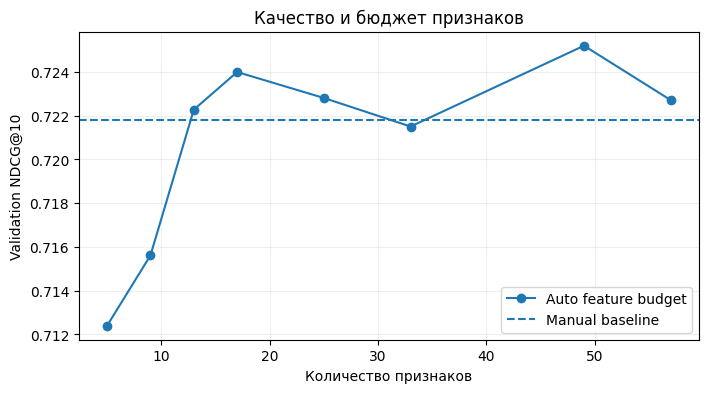

In [16]:
budget_rows = []
budget_models = {}
for k in [4, 8, 12, 16, 24, 32, 48, 56]:
    cols = ['genre'] + imp.head(k).index.tolist()
    name = f'Budget_{k}'
    model, secs = fit_model(cols)
    p = model.predict_proba(valid[cols])[:,1]
    scores = metrics(valid,p)
    budget_models[name] = (model,cols)
    budget_rows.append({'k_numeric':k, 'n_features':len(cols), 'fit_seconds':secs, **scores})
budget = pd.DataFrame(budget_rows)
display(budget)
budget.to_csv(OUT/'feature_budget_validation.csv',index=False)

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(budget['n_features'],budget['NDCG@10'],marker='o',label='Auto feature budget')
manual_p = models['Manual'].predict_proba(valid[manual])[:,1]
manual_ndcg = metrics(valid,manual_p)['NDCG@10']
ax.axhline(manual_ndcg,linestyle='--',label='Manual baseline')
ax.set(xlabel='Количество признаков',ylabel='Validation NDCG@10',
       title='Качество и бюджет признаков')
ax.legend();ax.grid(alpha=.2)
plt.show()
fig.savefig(OUT/'feature_budget.png',dpi=160,bbox_inches='tight')


## C. Абляция временных окон

Убираем **по одному временному окну** из полного автоматического набора и оцениваем на validation. Так проверяем, несёт ли конкретное окно дополнительную информацию в присутствии остальных. Это не причинная оценка.

,removed_window,n_features,fit_seconds,ROC-AUC,LogLoss,NDCG@10,delta_vs_all
0,3,49,30.848905,0.875057,0.152806,0.721889,-0.001164
4,60,49,31.139472,0.876004,0.151979,0.723322,0.000268
3,30,49,30.951772,0.875665,0.152384,0.723816,0.000763
1,7,49,30.933055,0.876203,0.152232,0.724445,0.001391
2,14,49,39.128060,0.876444,0.152000,0.724511,0.001458
5,120,49,30.469786,0.876557,0.152066,0.724839,0.001786


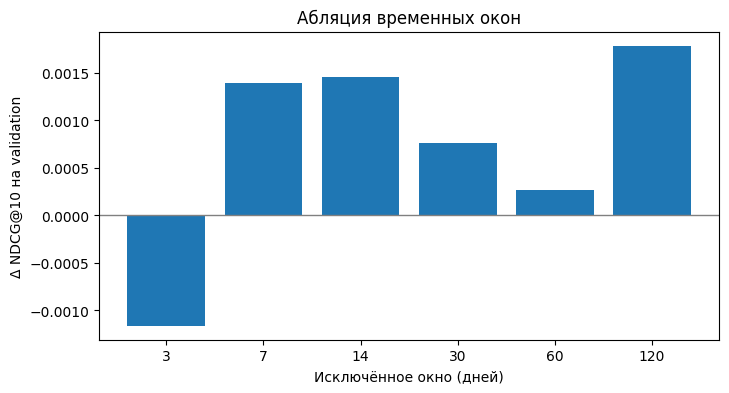

In [17]:
windows = [3,7,14,30,60,120]
ablation_rows = []
for w in windows:
    cols = [c for c in auto if not c.startswith(f'w{w}_')]
    model, secs = fit_model(cols)
    p = model.predict_proba(valid[cols])[:,1]
    sc = metrics(valid,p)
    ablation_rows.append({'removed_window':w,'n_features':len(cols),
                          'fit_seconds':secs,**sc})
ablation = pd.DataFrame(ablation_rows)
auto_all_val = metrics(valid,models['Auto_all'].predict_proba(valid[auto])[:,1])['NDCG@10']
ablation['delta_vs_all'] = ablation['NDCG@10'] - auto_all_val
display(ablation.sort_values('delta_vs_all'))
ablation.to_csv(OUT/'window_ablation_validation.csv',index=False)

fig, ax = plt.subplots(figsize=(8,4))
ax.bar(ablation['removed_window'].astype(str),ablation['delta_vs_all'])
ax.axhline(0,color='gray',linewidth=1)
ax.set(xlabel='Исключённое окно (дней)',ylabel='Δ NDCG@10 на validation',
       title='Абляция временных окон')
plt.show()
fig.savefig(OUT/'window_ablation.png',dpi=160,bbox_inches='tight')


## D. Автоматическая интерпретация и сохранение

Выводы ниже строятся только из фактических чисел. Доверительный интервал, содержащий ноль, **не подтверждает устойчивого отличия** при выбранной процедуре bootstrap.

In [18]:
lines = ['# Дополнительные эксперименты AutoFeatureRec','',
         '## Bootstrap по пользователям на исходном test',
         bootstrap.to_markdown(index=False,floatfmt='.5f'),'',
         '## Зависимость от бюджета признаков (validation)',
         budget.to_markdown(index=False,floatfmt='.5f'),'',
         '## Абляция окон (validation)',
         ablation.to_markdown(index=False,floatfmt='.5f'),'',
         '## Ограничения',
         '- Negative sampling исключает будущие положительные объекты: это офлайн-задача различения кандидатов, не онлайн-CTR.',
         '- KION содержит агрегированные просмотры с датой последнего просмотра, а не полный поток показов.',
         '- Тест исходных моделей уже изучен; дополнительные решения, принятые после его просмотра, требуют нового независимого теста.',
         '- Bootstrap отражает вариацию по пользователям при фиксированной выборке кандидатов и моделях.']
report = '\n'.join(lines)
(OUT/'research_addendum.md').write_text(report,encoding='utf-8')
print(report[:5500])
print('\nФайлы сохранены в',OUT)


# Дополнительные эксперименты AutoFeatureRec

## Bootstrap по пользователям на исходном test
| comparison            |   mean_delta |   ci_2.5% |   ci_97.5% |   n_users |
|:----------------------|-------------:|----------:|-----------:|----------:|
| Auto_top16 − Manual   |     -0.00303 |  -0.00630 |    0.00005 |      2754 |
| Hybrid_top16 − Manual |     -0.00006 |  -0.00287 |    0.00279 |      2754 |

## Зависимость от бюджета признаков (validation)
|   k_numeric |   n_features |   fit_seconds |   ROC-AUC |   LogLoss |   NDCG@10 |
|------------:|-------------:|--------------:|----------:|----------:|----------:|
|     4.00000 |      5.00000 |      24.41574 |   0.86419 |   0.15626 |   0.71240 |
|     8.00000 |      9.00000 |      26.53911 |   0.86667 |   0.15578 |   0.71561 |
|    12.00000 |     13.00000 |      28.29465 |   0.87552 |   0.15262 |   0.72227 |
|    16.00000 |     17.00000 |      27.25067 |   0.87591 |   0.15226 |   0.72399 |
|    24.00000 |     25.00000 |      28.29755 | 

In [20]:
from pathlib import Path
from google.colab import files
import shutil

# Папка с результатами экспериментов
print("Папка результатов:", OUT)
print("Содержимое:")

for path in Path(OUT).rglob("*"):
    if path.is_file():
        print(path.relative_to(OUT))

# Создаём ZIP-архив
archive = shutil.make_archive(
    "/content/AutoFeatureRec_results",
    "zip",
    root_dir=OUT
)

# Скачиваем на компьютер
files.download(archive)

Папка результатов: /content/autofeaturerec_results
Содержимое:
feature_budget_validation.csv
window_ablation_validation.csv
validation_metrics.csv
feature_budget.png
research_addendum.md
window_ablation.png
bootstrap_ndcg_test.csv
final_metrics.csv
feature_importance.csv
results.png
README.md


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>